# Iris Classification with k-Nearest Neighbors
Author: Manuel Eugenio Morocho Cayamcela, PhD

## Introduction
Use supervised learning to classify 150 Iris flowers into three species from four measurements: sepal length, sepal width, petal length, and petal width (in centimeters). This lesson covers loading data, exploration, preprocessing, training a k-nearest neighbors (k-NN) classifier, saving the model, and evaluating predictions.

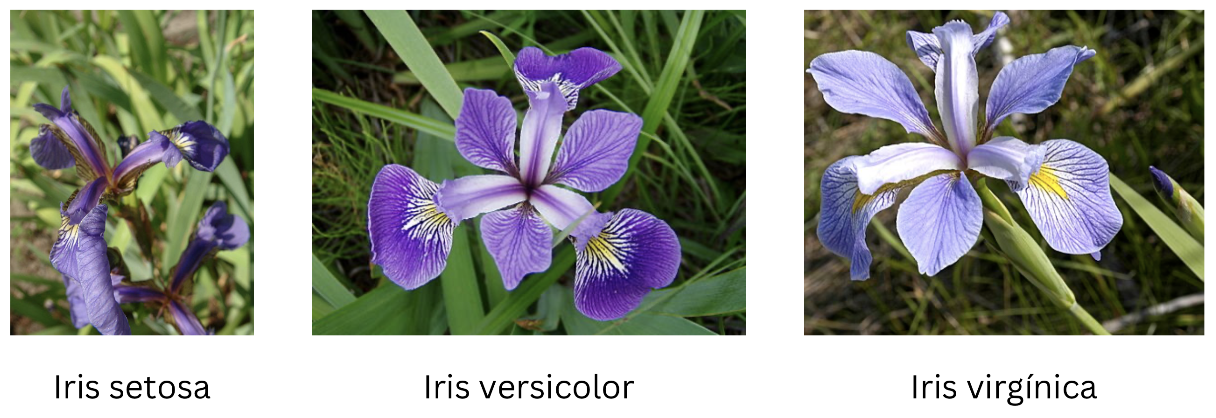

## Setup
If needed, install the packages once with `%pip install pandas matplotlib seaborn scikit-learn joblib`. Restart the kernel after installation if requested.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## Load the Iris dataset
Read the Iris CSV directly from GitHub using pandas. An internet connection is required.

In [2]:
github_url = "https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Datasets/iris.csv"
iris = pd.read_csv(github_url)

## Explore and prepare the data
Run each cell separately and inspect its output before continuing.

Preview the first five records.

In [3]:
iris.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Inspect column types and non-null counts to identify missing values.

In [4]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


Summarize the numeric columns.

In [5]:
iris.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


Count the examples of each species.

In [6]:
iris["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Remove `Id`: it identifies records rather than measuring flowers.

In [7]:
iris = iris.drop(columns="Id")

## Visualize the measurements
Compare sepal and petal measurements by species. Setosa is particularly distinct in petal measurements; versicolor and virginica overlap more. These plots help assess whether the measurements can separate the classes.

### Sepal measurements

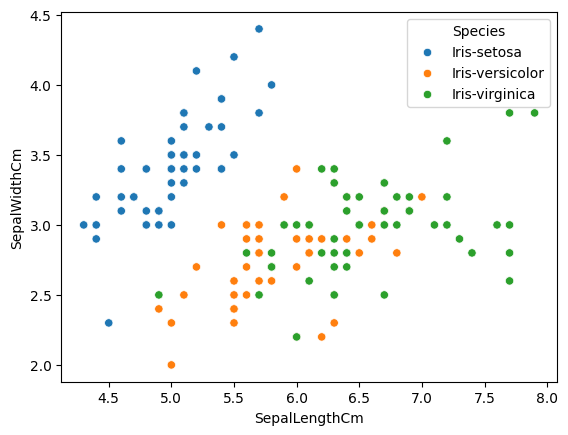

In [8]:
sns.scatterplot(data=iris, x="SepalLengthCm", y="SepalWidthCm", hue="Species")
plt.show()

### Petal measurements

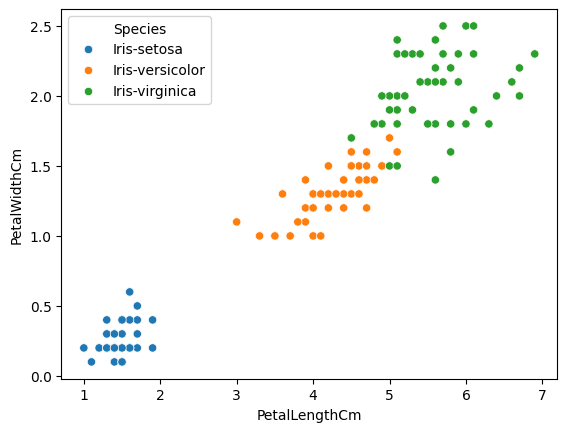

In [9]:
sns.scatterplot(data=iris, x="PetalLengthCm", y="PetalWidthCm", hue="Species")
plt.show()

The pair plot compares every pair of measurements. Histograms on the diagonal show each feature's distribution.

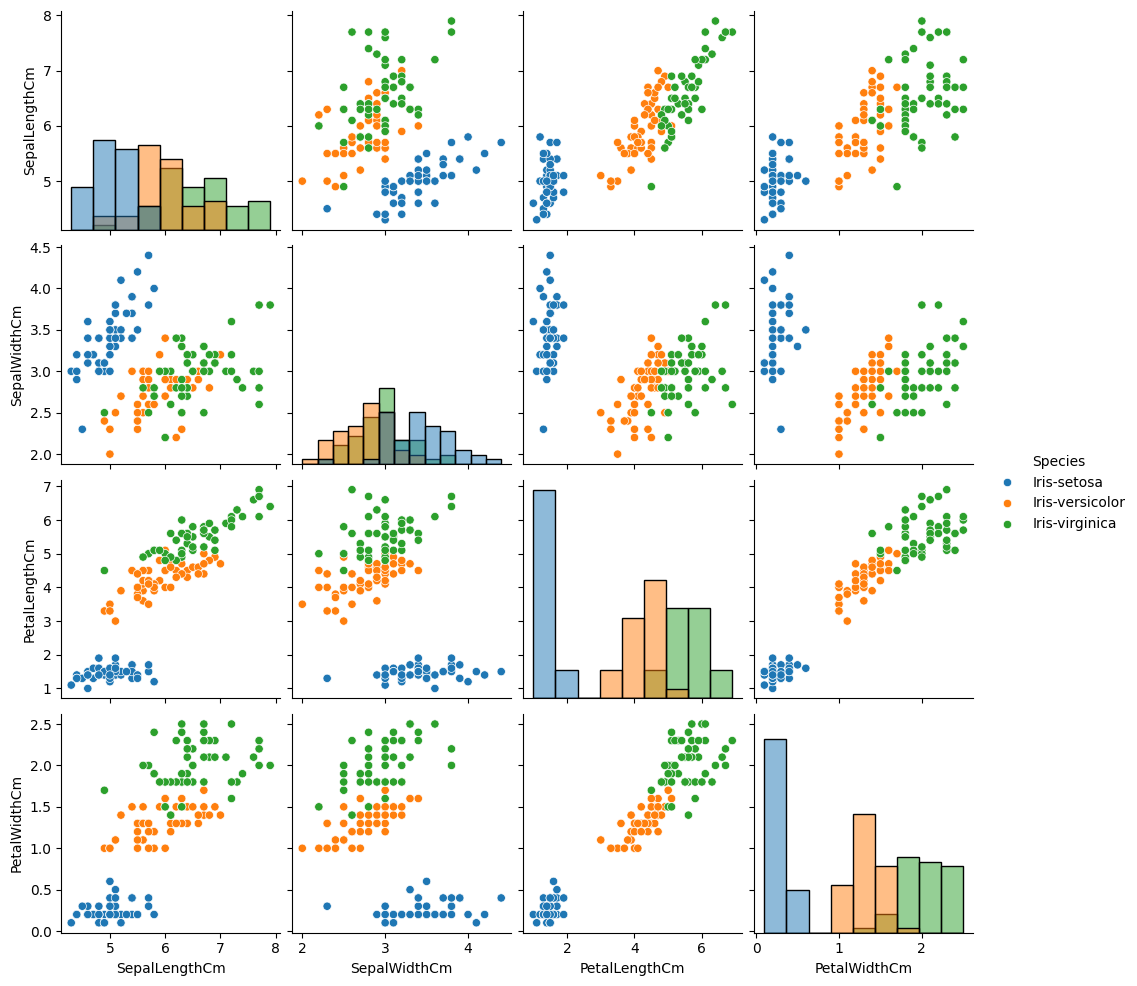

In [10]:
sns.pairplot(iris, hue="Species", diag_kind="hist")
plt.show()

## Prepare training and test sets
Separate the four predictors (`X`) from the species label (`y`). Reserve 20% of the data for testing. Stratification preserves class proportions, and a fixed random seed makes the split reproducible. Keep the test set out of model fitting.

In [11]:
# Isolate features
X = iris.drop(columns="Species")

# Isolate target variable
y = iris["Species"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## Train the k-NN classifier
With `n_neighbors=5`, the classifier predicts a flower's species from the majority class among its five nearest training examples. Fit the model on the training set only.

In [12]:
from sklearn.neighbors import KNeighborsClassifier

classifier = KNeighborsClassifier(n_neighbors=5)
classifier.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Iris-setosa','Iris-versicolor','Iris-virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## Evaluate on unseen data
Predict the species of the held-out examples.

In [13]:
predictions = classifier.predict(X_test)

### Accuracy
Accuracy is the fraction of correctly classified test examples.

In [14]:
print(f"Test accuracy: {accuracy_score(y_test, predictions):.3f}")

Test accuracy: 1.000


### Classification report
The report summarizes each species:

- **Precision:** TP / (TP + FP), the fraction of predictions for that species that are correct.
- **Recall:** TP / (TP + FN), the fraction of actual flowers of that species correctly identified.
- **F1-score:** the harmonic mean of precision and recall.
- **Support:** the number of true examples of that species in the test set.

Interpret the results generated below; scores can change with the split and model settings.

In [15]:
print(classification_report(y_test, predictions, zero_division=0))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



### Confusion matrix
Rows show actual classes and columns show predicted classes. Diagonal entries are correct predictions.

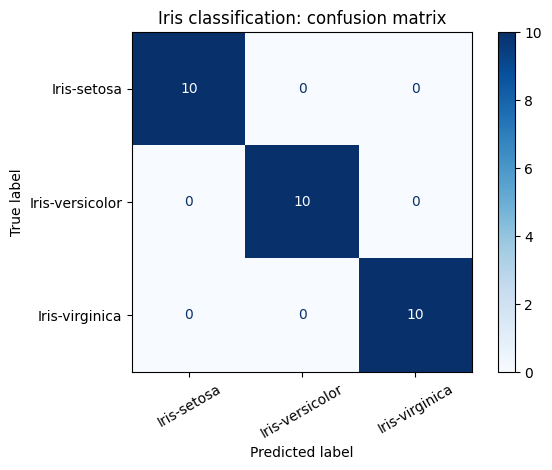

In [16]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=classifier.classes_, cmap="Blues"
)
plt.title("Iris classification: confusion matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Save and reload the trained model
Save the fitted classifier for reuse without retraining. Only load model files you trust. The file is written to the current working directory.

In [17]:
import joblib

model_path = Path("knn_model.pkl")
joblib.dump(classifier, model_path)

['knn_model.pkl']

In [18]:
loaded_classifier = joblib.load(model_path)
loaded_classifier.predict(X_test.head())

array(['Iris-setosa', 'Iris-virginica', 'Iris-versicolor',
       'Iris-versicolor', 'Iris-setosa'], dtype=object)

## Activity: Data Preprocessing and Customer Classification with k-NN
### Objective
Explore a classification dataset, train k-NN, and select a suitable value of `k`. Work individually or in a group, share the work fairly, and justify your decisions.

### Where to find datasets
For this short activity, choose a small tabular dataset with a clearly documented categorical target. Prefer CSV files and numeric predictors so that data preparation remains manageable.

- [UCI Machine Learning Repository](https://archive.ics.uci.edu/): a useful starting point for classification datasets.
- [Kaggle Datasets](https://www.kaggle.com/datasets): browse datasets and select one with a documented target and downloadable tabular files. Check access requirements before choosing it.
- [Awesome Public Datasets on GitHub](https://github.com/awesomedata/awesome-public-datasets): a topic-based directory linking to datasets; check the original source for files and documentation.
- [Ecuador Open Data Portal — CSV datasets](https://www.datosabiertos.gob.ec/dataset/?res_format=CSV): explore Ecuadorian public data available in CSV format.
- [INEC Open Data Bank](https://aplicaciones3.ecuadorencifras.gob.ec/BIINEC-war/index.xhtml): find Ecuadorian statistical information and consult the accompanying documentation.
- [U.S. Government Open Data](https://data.gov/): search public datasets by topic or organization.

Government portals are useful for local or applied topics, but their tables may require more cleaning and may not have a ready-made classification target. Verify the target column and download format before committing to a dataset.

### Instructions
1. **Find and explore a dataset (10 minutes).** Load a classification dataset, inspect its structure, and clean or transform it as needed.

In [19]:

# Import the dataset
import pandas as pd

bank = pd.read_csv("Churn_Modelling.csv")

# Verificar dimensiones y variables
print("Dimensiones:", bank.shape)

print("\nVariables disponibles:")
print(bank.columns.tolist())

# Mostrar registros iniciales
display(bank.head())

# Revisar valores faltantes
print("\nValores faltantes:")
print(bank.isnull().sum())

# Distribución de la variable objetivo
print("\nDistribución de Exited:")
print(bank["Exited"].value_counts())



Dimensiones: (10000, 14)

Variables disponibles:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Valores faltantes:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Distribución de Exited:
Exited
0    7963
1    2037
Name: count, dtype: int64


### Preparación de variables

Se eliminaron identificadores y nombres de clientes, y se transformaron las variables categóricas mediante *One-Hot Encoding*. El conjunto resultante contiene 13 variables predictoras y 10.000 registros, con `Exited` como variable objetivo.

In [20]:

# Seleccionar variables predictoras
X = bank.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"])

# Seleccionar variable objetivo
y = bank["Exited"]

# Convertir las variables categóricas en numéricas
X = pd.get_dummies(X, columns=["Geography", "Gender"], dtype=int)

# Verificar resultados
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

display(X.head())


Dimensiones de X: (10000, 13)
Dimensiones de y: (10000,)


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,1,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,1,0
3,699,39,1,0.00,2,0,0,93826.63,1,0,0,1,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,1,0


### División de datos de entrenamiento y prueba

Se dividió el dataset en 80 % para entrenamiento (8.000 clientes) y 20 % para prueba (2.000 clientes), utilizando una división estratificada para conservar la proporción de clientes que abandonaron el banco.

In [21]:

# Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Clientes de entrenamiento:", X_train.shape[0])
print("Clientes de prueba:", X_test.shape[0])

print("\nDistribución de clases en entrenamiento:")
print(y_train.value_counts())

print("\nDistribución de clases en prueba:")
print(y_test.value_counts())


Clientes de entrenamiento: 8000
Clientes de prueba: 2000

Distribución de clases en entrenamiento:
Exited
0    6370
1    1630
Name: count, dtype: int64

Distribución de clases en prueba:
Exited
0    1593
1     407
Name: count, dtype: int64


2. **Classify with k-NN (20 minutes).** Split the data into training and test sets, train the classifier, and report accuracy. Select `k` using only training data (for example, cross-validation), then evaluate the chosen model on the test set. Predict a new example outside both sets. Complete the random forest comparison in the companion notebook.

In [22]:

# Select the best k value for the k-NN classifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

# Escalado y clasificación KNN
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Valores de K que vamos a comparar
param_grid = {
    "knn__n_neighbors": list(range(1, 32, 2))
}

# Validación cruzada estratificada de 5 particiones
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Buscar el mejor K utilizando F1-score
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Mejor valor de K:", grid_search.best_params_["knn__n_neighbors"])
print("Mejor F1-score promedio:", round(grid_search.best_score_, 4))



Mejor valor de K: 1
Mejor F1-score promedio: 0.4738


In [23]:

# Fit a k-NN classifier to the training data
bank_classifier = grid_search.best_estimator_

print("Modelo KNN seleccionado:")
print(bank_classifier)


Modelo KNN seleccionado:
Pipeline(steps=[('scaler', StandardScaler()),
                ('knn', KNeighborsClassifier(n_neighbors=1))])


In [24]:

# Evaluar el modelo KNN con datos de prueba
bank_predictions = bank_classifier.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, bank_predictions), 4))

print("\nReporte de clasificación:")
print(classification_report(y_test, bank_predictions, zero_division=0))


Accuracy: 0.7905

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.87      0.87      0.87      1593
           1       0.48      0.47      0.48       407

    accuracy                           0.79      2000
   macro avg       0.68      0.67      0.67      2000
weighted avg       0.79      0.79      0.79      2000



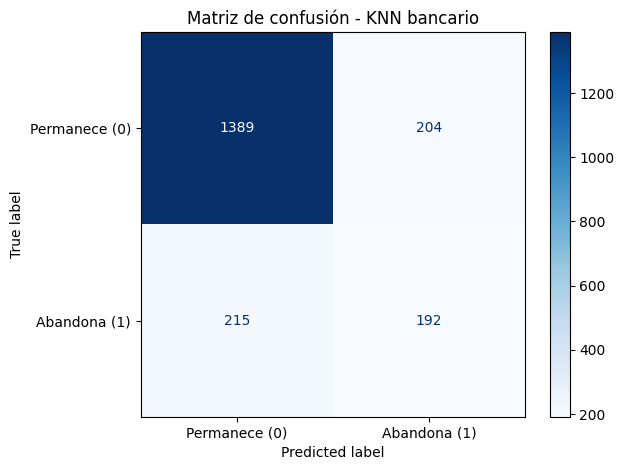

In [25]:

# Matriz de confusión del modelo KNN
ConfusionMatrixDisplay.from_predictions(
    y_test,
    bank_predictions,
    display_labels=["Permanece (0)", "Abandona (1)"],
    cmap="Blues"
)

plt.title("Matriz de confusión - KNN bancario")
plt.tight_layout()
plt.show()


### Predicción de un nuevo cliente

Se evaluó un cliente hipotético no incluido en los conjuntos de entrenamiento y prueba. El modelo KNN con K = 1 predijo la clase 0, correspondiente a la permanencia en el banco. Esta predicción debe interpretarse considerando las limitaciones del modelo para detectar abandonos.

In [26]:

# Predicción de un nuevo cliente hipotético
nuevo_cliente = pd.DataFrame([{
    "CreditScore": 650,
    "Age": 45,
    "Tenure": 3,
    "Balance": 120000,
    "NumOfProducts": 1,
    "HasCrCard": 1,
    "IsActiveMember": 0,
    "EstimatedSalary": 75000,
    "Geography_France": 1,
    "Geography_Germany": 0,
    "Geography_Spain": 0,
    "Gender_Female": 0,
    "Gender_Male": 1
}])

# Mantener las columnas en el mismo orden
nuevo_cliente = nuevo_cliente[X.columns]

prediccion = bank_classifier.predict(nuevo_cliente)[0]

print("Predicción:", prediccion)
print("Resultado:", "Abandonará el banco" if prediccion == 1 else "Permanecerá en el banco")


Predicción: 0
Resultado: Permanecerá en el banco


### Evaluación del modelo KNN

El modelo obtuvo un Accuracy de 79,05 % y un F1-score de 0,48 para la clase de abandono. La matriz de confusión muestra 1.389 verdaderos negativos, 192 verdaderos positivos, 204 falsos positivos y 215 falsos negativos. Estos resultados evidencian dificultades para detectar clientes que abandonan el banco.

3. **Present the dataset and process (30 minutes).** Explain decisions and results, and discuss possible improvements.


Write a brief explanation of the dataset, preprocessing steps, and model evaluation...


### Análisis de resultados: clasificación bancaria con KNN

**Dataset:** Se utilizó *Bank Customer Churn* de Kaggle, con 10.000 registros y la variable objetivo `Exited` (0: permanencia; 1: abandono). El 20,37 % de los clientes pertenece a la clase de abandono.

**Preprocesamiento:** Se eliminaron identificadores y nombres, se codificaron las variables categóricas y se dividieron los datos de forma estratificada: 80 % entrenamiento y 20 % prueba. Se aplicó `StandardScaler` dentro de un pipeline para evitar fugas de información.

**Selección de K:** Se compararon 16 valores impares entre 1 y 31 mediante validación cruzada estratificada de cinco particiones, utilizando F1-score como criterio. Se seleccionó K = 1, con un F1-score promedio de 0,4738.

**Evaluación:** El modelo obtuvo un Accuracy del 79,05 %, Precision del 48 %, Recall del 47 % y F1-score del 48 % para la clase de abandono. Se identificaron correctamente 192 abandonos, pero 215 no fueron detectados.

**Conclusión y mejoras:** Aunque el modelo presenta una exactitud global aceptable, su capacidad para detectar abandonos es limitada. Se recomienda evaluar técnicas para tratar el desbalance de clases, ajustar parámetros adicionales y comparar su rendimiento con Random Forest.

### Assessment
- Dataset source: 10%.
- Training/test split: 20%.
- Justification of the chosen `k`: 40%.
- Classification metrics: 30%.

### Deliverable
Submit the Jupyter notebook results as a PDF.